In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# 05 - Consumer Trust scoring
CTS (survey) + Platform Security Index (measured) → Consumer Trust Index. Includes a **sensitivity analysis** because the weights are a design choice, not a measured constant.

In [2]:
from src.trust_scoring.scoring import *
sv = load_survey(); sc = score_respondents(sv, CFG); summ = load_summary()
print(CFG['trust']['weights'])
sc.trust_score.describe().round(1)

{'perceived_security': 0.3, 'privacy_assurance': 0.2, 'transparency': 0.15, 'reliability': 0.2, 'behavioural_intent': 0.15}


count    355.0
mean      56.6
std       17.1
min       10.0
25%       46.2
50%       56.2
75%       67.5
max       95.6
Name: trust_score, dtype: float64

In [3]:
m = summ['models']['results'][summ['models']['champion']]
psi = platform_security_index(m['recall'], m['false_positive_rate'], summ['security']['attack_block_rate'], summ['validation']['pass_rate'])
cti = consumer_trust_index(sc.trust_score.mean(), psi, CFG['trust']['survey_weight_in_index'])
print(f'PSI={psi:.1f}  mean CTS={sc.trust_score.mean():.1f}  CTI={cti:.1f}')

PSI=79.8  mean CTS=56.6  CTI=65.8


<Axes: title={'center': 'CTI vs survey weight'}, xlabel='survey_weight'>

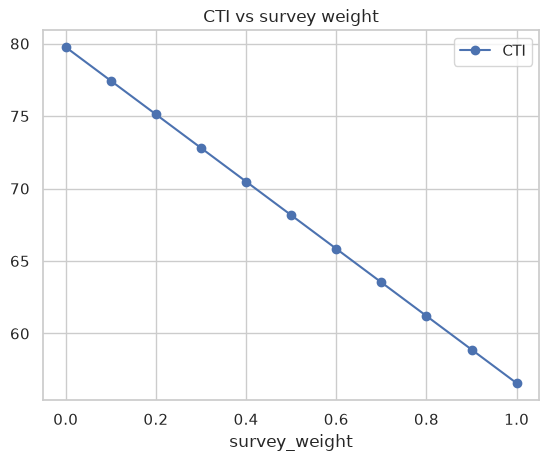

In [4]:
# sensitivity 1: weight on the survey component
grid = pd.DataFrame({'survey_weight': np.linspace(0, 1, 11)}); grid['CTI'] = [consumer_trust_index(sc.trust_score.mean(), psi, a) for a in grid.survey_weight]
grid.plot(x='survey_weight', y='CTI', marker='o', title='CTI vs survey weight')

In [5]:
# sensitivity 2: random dimension weights (Dirichlet) -> how stable is the respondent ranking?
from scipy.stats import spearmanr
dims = dimension_scores(sv); base = sc.trust_score
rng = np.random.default_rng(0); rhos = []
for _ in range(500):
    w = rng.dirichlet(np.ones(5)); rhos.append(spearmanr(base, dims.to_numpy() @ w).statistic)
print(f'Rank correlation with default weights: median {np.median(rhos):.3f}, 5th pct {np.percentile(rhos, 5):.3f}')

Rank correlation with default weights: median 0.962, 5th pct 0.905


In [6]:
print({k: round(v, 3) for k, v in reliability_report(sv).items()})

{'overall': 0.906, 'perceived_security': 0.838, 'privacy_assurance': 0.601, 'transparency': 0.517, 'reliability': 0.49, 'behavioural_intent': 0.647}


Rankings are robust to weighting (rho close to 1) while the *level* of CTI depends on the chosen survey weight - report both. CTI is a proposed composite, not a validated instrument.